# 12 · People suggestions (E7)

**Experiment E7.** BOING now suggests people as well as groups: "People you may know" on the Discover page, built into
BOING on 19 November 2026 (`boing-backend/recs.js`, functions `makePeople`, `eligible` and `peopleOut`). It follows the same
values and rules as the group recommender, with R8 as its people rule. This notebook evaluates it on the synthetic community,
with the same seed discipline as notebooks 01 to 11.

**The design, as built.**
- *Candidates:* friends of friends, and members of the member's groups and course rooms.
- *Never suggested:* the member, current friends, pending requests either way, anyone blocked either way, suspended accounts,
  private profiles, people not taking friend requests, people who did not switch suggestions on (being suggested is opt-in too),
  and people the member dismissed ("Not interested").
- *The age bands (R8; the owner's rule of 19 November 2026).* From the private birth year, used only as a safety filter; an
  unknown age counts as under 18.
  - Under 14: no personalised suggestions, and never suggested to anyone.
  - A viewer aged 14 to 17 sees other minors as usual, and adults aged 18 to 20 only through a mutual friend or a shared group or
    course; never anyone over 20.
  - A viewer aged 18 to 20 sees a minor only if they are classmates (the same course this term).
  - A viewer over 20 never sees a minor.
- *Score:* mutual friends + shared groups (no learning). *Reason:* the bigger one ("3 mutual friends", or "You're both in X",
  naming the smallest shared group that is listed to everyone, or "You're in 2 groups together"). At most 2 people for the
  same named group. Five at most, no notifications; members who did not switch suggestions on get no list (R1).

**What we measure** (planned before the run):
- *Relevance:* hide 20% of the friendships; do the five suggestions find them? Hit rate and NDCG@5 against three baselines
  (random, the most-connected people, mutual friends only) and shared groups only. The weight of shared groups is checked on a
  practice quiz carved out of the training friendships, never on the test.
- *Normative outcomes:* rule violations (target 0) over every list, on planted test cases (blocked, private, suspended, not
  switched on, every age pair) and with faults planted on purpose; exposure concentration (do a few popular people take the
  slots? Gini, the top 10%'s share, newcomers' share); what the safety, age and consent rules cost in relevance; and what each
  age rule gives minors and exposes them to.

**Hypotheses.** H1: the design beats random and the most-connected people on relevance. H2: zero violations, every age pair
as the rule says. H3: exposure is far less concentrated than ranking by connections. H4: consent (opt-in) costs the most
relevance, and the age bands give minors more than a strict adult/minor line without showing them to anyone over 20.

**Version 2 (19 Nov 2026).** The first run used the community's own friendships, which almost never close a triangle, so every
method found few friends and the weights were tuned for that world. The main world is now a realistic friendship model fixed before
any test result was seen (section 1): friendships form in shared groups and classes and close triangles, more readily when the two
share a group or course (Kossinets & Watts, 2006), until the average clustering reaches 0.15. The weight of shared groups is tuned on
that world's practice quiz, and the first world is kept as a sensitivity check (section 8).

Run notebooks 01 and 02 first. The code is section 13 of `boingrec.py`, in this folder.

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import json
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import boingrec as br

SEED, K = br.SEED, br.K          # 0 and 5, as in every notebook
br.use_style()
D = br.DATA
METHODS7 = {'random': 'Random', 'popular': 'Most connected', 'mutual': 'Mutual friends only',
            'groups': 'Shared groups only', 'boing': 'BOING design'}

## 1 · What we add to the synthetic community, and why

The community of notebook 01 has no ages, no course rooms and no suggestion switch. E7 adds them with these assumptions
(`br.PEOPLE_ASSUME`, `br.AGE_SHARES`); every draw is seeded, and a larger share always contains the smaller one.

| Addition | Assumption | Why |
|---|---|---|
| Age | 13: 0.5%; 14 to 16: 1.5%; 17: 6%; 18, 19 and 20: 15% each; 21 to 24: 32%; 25 to 29: 10%; no birth year: 5% (counted as under 18) | BOING launches at McGill: most members are 18 to 24, first-years are often 17, BOING's minimum age is 14, and a few early accounts gave no birth year. The 13-year-olds test the under-14 rule. Ages are drawn independently of the network (see the limits) |
| Course rooms this term | 160 rooms, 40 at each of 4 year levels; each student takes 4 at their level and 1 elective; intro courses are bigger (Zipf weights). Level from age: 17 and under year 1; 18 year 1; 19 year 1 or 2; 20 year 2 or 3; 21 year 3 or 4; 22 and over year 4. Under-14s take none | The age rule's classmate condition needs courses; BOING counts course rooms as groups |
| Friendships made in class | 1,000 more (a random student befriends a random classmate), on top of sim_v1's 5,374 | Classmates do become friends; without these, shared courses would predict nothing |
| Friends of friends (version 2, the main world) | Friendships that close a triangle are added (a friend's friend, accepted always if the two share a group or course, else 30% of the time) until the average local clustering coefficient reaches 0.15 | Real networks close triangles, most often around shared foci such as classes (Kossinets & Watts, 2006), and are highly clustered: 0.14 for Facebook users with 100 friends, higher for fewer (Ugander et al., 2011); our members have about 10 friends, so 0.15 is conservative (this generator levels off near 0.17). Fixed before any test result was seen |
| Suggestion switch | 25% switched on (E3's assumption); 10% to 100% as a sensitivity | Being suggested is opt-in, with the same switch as seeing suggestions |
| Not taking friend requests | 5% | A BOING setting: such people are never suggested |
| Tie-break | a random key per member | BOING sorts equal scores by the member's random id; our ids follow sign-up order |

Pending requests and "Not interested" for people do not exist in the community; they appear only in the planted test cases.

In [3]:
users = pd.read_csv(D / 'users.csv', usecols=['user_id', 'created_day', 'level', 'privacy', 'suspended'])
groups = pd.read_csv(D / 'groups.csv', usecols=['group_id', 'name', 'open', 'created_day', 'hidden_by_mods'])
memberships = pd.read_csv(D / 'memberships.csv')     # inputs here, not answers: E7's answers are hidden friendships
blocks = pd.read_csv(D / 'blocks.csv')
draws, courses = br.people_attributes(users)
first_world = br.add_class_friendships(pd.read_csv(D / 'friendships.csv'), courses, blocks, br.PEOPLE_ASSUME['class_friends'])
friendships, n_closure, clustering = br.add_focal_closure(first_world, users, memberships, courses, blocks)
clustering_first = br.avg_clustering(first_world, users.user_id.to_numpy())
print(f'Main world: {len(friendships):,} friendships ({n_closure:,} close a triangle), average clustering {clustering:.3f}; '
      f'the first world: {len(first_world):,} friendships, clustering {clustering_first:.3f}')

band = br.age_band(draws.sort_values('user_id').age.to_numpy())
print(f"{len(users):,} members, {len(friendships):,} friendships, "
      f"{courses.group_id.nunique()} course rooms, {len(courses):,} course enrolments "
      f"(median room {courses.groupby('group_id').size().median():.0f} students, largest {courses.groupby('group_id').size().max()})")
print('Age bands:', {br.BANDS[b]: int((band == b).sum()) for b in range(4)}, '| no birth year:', int((draws.age == br.UNKNOWN_AGE).sum()))

Main world: 9,374 friendships (3,000 close a triangle), average clustering 0.153; the first world: 6,374 friendships, clustering 0.007
2,000 members, 9,374 friendships, 160 course rooms, 9,930 course enrolments (median room 42 students, largest 499)
Age bands: {'under 14': 12, '14-17 or unknown': 256, '18-20': 870, '21 and over': 862} | no birth year: 102


## 2 · The test: 20% of the friendships hidden

As in notebook 02, but for friendships: 20% of all friendships are hidden at random (seed 0) and form the test. A member with at
least one hidden friend (not suspended) is tested; their hidden friends are the right answers. The practice quiz hides 20% of the
remaining friendships again, inside the training data. Every method sees only the training friendships.

In [4]:
def truth_of(w, hidden):
    pos = pd.Series(np.arange(len(w.ids)), index=w.ids)
    t = {}
    for a, b in zip(hidden.user_a, hidden.user_b):
        t.setdefault(pos[a], set()).add(pos[b]); t.setdefault(pos[b], set()).add(pos[a])
    return {i: s for i, s in sorted(t.items()) if not w.suspended[i]}

train_f, test_f = br.split_friendships(friendships)
w = br.people_world(users, groups, memberships, courses, train_f, blocks, draws)
sig = br.people_signals(w)
truth = truth_of(w, test_f)
askers = sorted(truth)
fit_f, val_f = br.split_friendships(train_f)                 # the practice quiz, inside the training friendships
wv = br.people_world(users, groups, memberships, courses, fit_f, blocks, draws)
sigv = br.people_signals(wv)
truth_v = truth_of(wv, val_f)
reach = br.people_allowed(w, br.PEOPLE_RULES, sig)
best_hit = float(np.mean([any(reach[i, j] for j in s) for i, s in truth.items()]))
print(f'Test: {len(test_f):,} hidden friendships, {len(askers):,} members tested; practice quiz: {len(val_f):,} friendships, '
      f'{len(truth_v):,} members')
print(f'Best possible hit rate under every rule (a hidden friend who may be suggested at all): {best_hit:.3f}')

Test: 1,875 hidden friendships, 1,617 members tested; practice quiz: 1,500 friendships, 1,498 members
Best possible hit rate under every rule (a hidden friend who may be suggested at all): 0.321


## 3 · Practice quiz: the weight of shared groups

BOING's score adds mutual friends and shared groups with equal weight (w = 1), a choice made when it was built, not tuned. We tune
w on the practice quiz only (never on the test): the design uses the w with the best NDCG@5 there, and BOING as built (w = 1) is
reported beside it. (w = 0 ranks friends of friends by mutual friends alone, then members of shared groups at random.) We also try
shared groups weighted by 1/log(size) (a rare shared group says more; Adamic & Adar, 2003), as a lead only.

In [5]:
rows = []
for wt in [0, 0.05, 0.1, 0.25, 0.5, 1, 2]:
    r = br.people_relevance(br.suggest_people(wv, sorted(truth_v), signals=sigv, weight=wt), truth_v)
    rows.append({'score': f'mutual + {wt} x shared', 'w': wt, 'hit_rate': r.hit_rate.mean(), 'ndcg@5': r['ndcg@5'].mean()})
inv = 1 / np.log(np.maximum(wv.group_size, 2))
aa = (wv.groups * inv) @ wv.groups.T
r = br.people_relevance(br.suggest_people(wv, sorted(truth_v), signals=(sigv[0], aa, sigv[2])), truth_v)
rows.append({'score': 'mutual + shared, each group weighted 1/log(size)', 'w': np.nan, 'hit_rate': r.hit_rate.mean(),
             'ndcg@5': r['ndcg@5'].mean()})
validation = pd.DataFrame(rows)
br.save_table(validation.set_index('score'), 'e7_validation.csv', decimals=4)
grid = validation.dropna(subset=['w'])
W = float(grid.loc[grid['ndcg@5'].idxmax(), 'w'])
import functools
suggest = functools.partial(br.suggest_people, weight=W)      # the design, with the tuned weight, from here on
print(f'Chosen on the practice quiz: w = {W}')
validation.round(4)

Chosen on the practice quiz: w = 0.05


,score,w,hit_rate,ndcg@5
0,mutual + 0 x shared,0.00,0.0801,0.0330
1,mutual + 0.05 x shared,0.05,0.0895,0.0409
2,mutual + 0.1 x shared,0.10,0.0895,0.0409
3,mutual + 0.25 x shared,0.25,0.0841,0.0388
4,mutual + 0.5 x shared,0.50,0.0621,0.0296
5,mutual + 1 x shared,1.00,0.0387,0.0185
6,mutual + 2 x shared,2.00,0.0334,0.0148
7,"mutual + shared, each group weighted 1/log(size)",NaN,0.0941,0.0430


## 4 · Relevance against the baselines (test)

Every method sees the same allowed set (every rule on), so the comparison is about the scoring. 95% ranges come from resampling
the tested members (2,000 resamples, seed 0). "BOING design, no rules" is the same score with only "not me, not a friend" (and no variety rule).

In [6]:
lists, rel = {}, {}
for m in METHODS7:
    lists[m] = suggest(w, askers, method=m, signals=sig)
    rel[m] = br.people_relevance(lists[m], truth)
lists['norules'] = suggest(w, askers, signals=sig, rules=('self', 'friend'), variety=False)
lists['built'] = br.suggest_people(w, askers, signals=sig, weight=1.0)
rel['built'] = br.people_relevance(lists['built'], truth)
rel['norules'] = br.people_relevance(lists['norules'], truth)

# exposure: the lists of every member who switched suggestions on (R1), over the people who may be suggested
served = [i for i in range(len(w.ids)) if not w.suspended[i]]
pool = ~w.suspended & ~w.private & w.opted_in & w.takes_requests & (w.band > 0)
rows = []
NAMES = {**METHODS7, 'norules': 'BOING design, no rules', 'built': 'BOING as built (w = 1)'}
for m in list(METHODS7) + ['built', 'norules']:
    r = rel[m]
    hl, hh = br.bootstrap_ci(r.hit_rate)
    nl, nh = br.bootstrap_ci(r['ndcg@5'])
    row = {'method': NAMES[m], 'hit_rate': r.hit_rate.mean(), 'hit_low': hl, 'hit_high': hh,
           'ndcg@5': r['ndcg@5'].mean(), 'ndcg_low': nl, 'ndcg_high': nh, 'mean_length': r.length.mean(),
           'empty_lists': (r.length == 0).mean()}
    if m != 'norules':
        e = br.people_exposure((br.suggest_people(w, served, signals=sig, weight=1.0, only_opted_in=True) if m == 'built'
                                else suggest(w, served, method=m, signals=sig, only_opted_in=True)), w, pool)
        row.update({'gini': e['gini'], 'top10_share': e['top10_share'], 'coverage': e['coverage'],
                    'newcomers_share_of_slots': e['new_share_of_slots'], 'newcomers_share_of_pool': e['new_share_of_pool'],
                    'slots': e['slots'], 'pool': e['pool']})
    rows.append(row)
methods_table = pd.DataFrame(rows).set_index('method')
br.save_table(methods_table, 'e7_methods.csv', decimals=4)
# the slice: members with 0 or 1 friends in the training data (newcomers, mostly), where mutual friends cannot help
nfriends = w.friends.sum(axis=1)
few = [i for i in askers if nfriends[i] <= 1]
slice_rows = [{'method': NAMES[m], 'members': len(few), 'hit_rate': rel[m].loc[few].hit_rate.mean(),
               'ndcg@5': rel[m].loc[few]['ndcg@5'].mean(), 'empty_lists': (rel[m].loc[few].length == 0).mean()}
              for m in list(METHODS7) + ['built']]
few_table = pd.DataFrame(slice_rows).set_index('method')
br.save_table(few_table, 'e7_few_friends.csv', decimals=4)
print(f'Members tested with 0 or 1 friends: {len(few)}')
display(methods_table.round(4)); few_table.round(4)

Members tested with 0 or 1 friends: 28


,hit_rate,hit_low,hit_high,ndcg@5,ndcg_low,ndcg_high,mean_length,empty_lists,gini,top10_share,coverage,newcomers_share_of_slots,newcomers_share_of_pool,slots,pool
method,,,,,,,,,,,,,,,
Random,0.0080,0.0037,0.0124,0.0022,0.0010,0.0037,4.9784,0.0043,0.2423,0.1794,0.9972,0.1560,0.1524,2480.0,361.0
Most connected,0.0093,0.0049,0.0142,0.0029,0.0014,0.0046,4.9784,0.0043,0.9823,1.0000,0.0499,0.0000,0.1524,2480.0,361.0
Mutual friends only,0.1293,0.1138,0.1459,0.0581,0.0499,0.0670,4.4552,0.0247,0.4795,0.3089,0.9141,0.0693,0.1524,2192.0,361.0
Shared groups only,0.0315,0.0235,0.0408,0.0109,0.0078,0.0145,4.9784,0.0043,0.5548,0.3637,0.8726,0.0383,0.1524,2480.0,361.0
BOING design,0.1577,0.1404,0.1756,0.0708,0.0618,0.0801,4.9784,0.0043,0.3976,0.2484,0.9612,0.0544,0.1524,2480.0,361.0
BOING as built (w = 1),0.0736,0.0612,0.0872,0.0312,0.0247,0.0376,4.9784,0.0043,0.5283,0.3387,0.9003,0.0387,0.1524,2480.0,361.0
"BOING design, no rules",0.3927,0.3692,0.4168,0.1907,0.1763,0.2049,5.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,members,hit_rate,ndcg@5,empty_lists
method,,,,
Random,28,0.0357,0.0225,0.0000
Most connected,28,0.0000,0.0000,0.0000
Mutual friends only,28,0.1429,0.0601,0.4286
Shared groups only,28,0.0357,0.0072,0.0000
BOING design,28,0.1786,0.0869,0.0000
BOING as built (w = 1),28,0.0714,0.0251,0.0000


## 5 · What the rules cost (test)

The design's score, with the rules added one group at a time (variety, at most 2 per named group, comes last). Each cost is
against the step before, with a paired 95% range.

In [7]:
steps = dict(br.PEOPLE_STEPS)
prev, rows = None, []
for name, rules in list(steps.items()) + [('+ Variety (at most 2 people per named group): the BOING design', br.PEOPLE_RULES)]:
    r = br.people_relevance(suggest(w, askers, signals=sig, rules=rules, variety='Variety' in name), truth)
    row = {'step': name, 'hit_rate': r.hit_rate.mean(), 'ndcg@5': r['ndcg@5'].mean()}
    if prev is not None:
        d = prev['ndcg@5'] - r['ndcg@5']
        lo, hi = br.bootstrap_ci(d)
        row.update({'cost': d.mean(), 'cost_low': lo, 'cost_high': hi})
    rows.append(row)
    prev = r
costs = pd.DataFrame(rows).set_index('step')
d = rel['norules']['ndcg@5'] - rel['boing']['ndcg@5']
costs.loc['Every rule together', ['ndcg@5', 'cost', 'cost_low', 'cost_high']] = [rel['boing']['ndcg@5'].mean(), d.mean(), *br.bootstrap_ci(d)]
br.save_table(costs, 'e7_costs.csv', decimals=4)
costs.round(4)

,hit_rate,ndcg@5,cost,cost_low,cost_high
step,,,,,
No rules (score only),0.3927,0.1907,NaN,NaN,NaN
"+ Safety filters (R8: blocked either way, suspended, private)",0.3513,0.1667,0.0239,0.0159,0.0322
+ Age bands (R8),0.3370,0.1605,0.0062,0.0017,0.0109
+ Consent (R1: only people who switched on and take requests),0.1571,0.0707,0.0898,0.0758,0.1030
+ Variety (at most 2 people per named group): the BOING design,0.1577,0.0708,-0.0001,-0.0009,0.0008
Every rule together,NaN,0.0708,0.1199,0.1046,0.1349


## 6 · The age rule: belonging against safety

Three age rules, the rest of the design unchanged: none; the earlier binary line (adults and under-18s never mixed); and the
owner's bands. For each: relevance by the viewer's band (test), and, over every list of the members who switched on, how often a
minor (14 to 17, or no birth year) is shown to an adult, and through which link.

In [8]:
abands = np.array([w.band[i] for i in askers])
mutual, shared, crs = sig
rows, links = [], []
for label, rules, rule in [('No age rule', tuple(x for x in br.PEOPLE_RULES if x != 'age'), None),
                           ('Binary line (adults and under-18s apart)', br.PEOPLE_RULES, 'binary'),
                           ("Age bands (the owner's rule)", br.PEOPLE_RULES, None)]:
    r = br.people_relevance(suggest(w, askers, signals=sig, rules=rules, age_rule=rule), truth)
    row = {'rule': label, 'ndcg@5 (everyone)': r['ndcg@5'].mean(), 'hit_rate (everyone)': r.hit_rate.mean()}
    for b in range(4):
        row[f'hit_rate ({br.BANDS[b]})'] = r.hit_rate[abands == b].mean()
        row[f'ndcg@5 ({br.BANDS[b]})'] = r['ndcg@5'][abands == b].mean()
    allL = suggest(w, served, signals=sig, rules=rules, age_rule=rule, only_opted_in=True)
    c = {'minor to 21+': 0, 'minor to 18-20, classmates': 0, 'minor to 18-20, not classmates': 0, 'under-14 shown or served': 0,
         '18-20 shown to a minor': 0, 'all slots': 0}
    for i, items in allL.items():
        for j, _ in items:
            c['all slots'] += 1
            if w.band[i] == 0 or w.band[j] == 0:
                c['under-14 shown or served'] += 1
            elif w.band[j] == 1 and w.band[i] == 3:
                c['minor to 21+'] += 1
            elif w.band[j] == 1 and w.band[i] == 2:
                c['minor to 18-20, classmates' if crs[i, j] > 0 else 'minor to 18-20, not classmates'] += 1
            if w.band[i] == 1 and w.band[j] == 2:
                c['18-20 shown to a minor'] += 1
    rows.append(row); links.append({'rule': label, **c})
age_rules = pd.DataFrame(rows).set_index('rule').join(pd.DataFrame(links).set_index('rule'))
minors_tested = int((abands == 1).sum())
br.save_table(age_rules, 'e7_age_rules.csv', decimals=4)
print(f'Tested minors (14 to 17, or no birth year): {minors_tested}; under-14s tested: {int((abands == 0).sum())}')
age_rules.T.round(4)

Tested minors (14 to 17, or no birth year): 201; under-14s tested: 7


rule,No age rule,Binary line (adults and under-18s apart),Age bands (the owner's rule)
ndcg@5 (everyone),0.0748,0.0654,0.0708
hit_rate (everyone),0.1676,0.1472,0.1577
hit_rate (under 14),0.1429,0.0000,0.0000
ndcg@5 (under 14),0.0377,0.0000,0.0000
hit_rate (14-17 or unknown),0.1095,0.0249,0.0896
ndcg@5 (14-17 or unknown),0.0587,0.0117,0.0435
hit_rate (18-20),0.1662,0.1547,0.1605
ndcg@5 (18-20),0.0717,0.0672,0.0705
hit_rate (21 and over),0.1857,0.1758,0.1758
ndcg@5 (21 and over),0.0827,0.0795,0.0795


## 7 · Consent: how many switch on?

Being suggested is opt-in, so the share who switch on decides who can be found. The same test, with 10% to 100% switched on
(nested draws: the 10% are among the 25%...).

In [9]:
rows = []
for p in [0.1, 0.25, 0.5, 0.75, 1.0]:
    wp = br.people_world(users, groups, memberships, courses, train_f, blocks, draws, assume={'opt_in': p})
    r = br.people_relevance(suggest(wp, askers, signals=sig), truth)
    al = br.people_allowed(wp, br.PEOPLE_RULES, sig)
    rows.append({'switched on': p, 'hit_rate': r.hit_rate.mean(), 'ndcg@5': r['ndcg@5'].mean(),
                 'best possible hit rate': np.mean([any(al[i, j] for j in s) for i, s in truth.items()])})
opt_in = pd.DataFrame(rows).set_index('switched on')
br.save_table(opt_in, 'e7_opt_in.csv', decimals=4)
opt_in.round(4)

,hit_rate,ndcg@5,best possible hit rate
switched on,,,
0.10,0.0847,0.0409,0.1416
0.25,0.1577,0.0708,0.3210
0.50,0.2325,0.1072,0.5294
0.75,0.3092,0.1432,0.7174
1.00,0.3259,0.1552,0.8287


## 8 · Sensitivity: the first world, where friends of friends almost never become friends

Version 1's world (sim_v1's friendships and the classmate friendships, without the triangle-closing ones): every method is compared
again, the design with the weight tuned on the main world.

In [10]:
def tri_share(f):
    nb = {}
    for a, b in zip(f.user_a, f.user_b):
        nb.setdefault(a, set()).add(b); nb.setdefault(b, set()).add(a)
    return float(np.mean([len(nb[a] & nb[b]) > 0 for a, b in zip(f.user_a, f.user_b)]))

closure_f = first_world
trc, tec = br.split_friendships(closure_f)
wc = br.people_world(users, groups, memberships, courses, trc, blocks, draws)
sigc = br.people_signals(wc)
truth_c = truth_of(wc, tec)
rows = []
for m in METHODS7:
    r = br.people_relevance(suggest(wc, sorted(truth_c), method=m, signals=sigc), truth_c)
    rows.append({'method': METHODS7[m], 'hit_rate': r.hit_rate.mean(), 'ndcg@5': r['ndcg@5'].mean()})
closure = pd.DataFrame(rows).set_index('method')
tri = {'main world': tri_share(friendships), 'first world': tri_share(first_world)}
br.save_table(closure, 'e7_closure.csv', decimals=4)
print('Share of friendships whose two friends share a friend:', {k: round(v, 3) for k, v in tri.items()})
closure.round(4)

Share of friendships whose two friends share a friend: {'main world': 0.729, 'first world': 0.044}


,hit_rate,ndcg@5
method,,
Random,0.0043,0.0019
Most connected,0.0072,0.0025
Mutual friends only,0.0064,0.0020
Shared groups only,0.0200,0.0081
BOING design,0.0165,0.0061


## 9 · Do the rules hold?

Four checks, by `br.check_people()`, which recomputes everything from the raw tables (friend lists, memberships, courses, ages,
settings) rather than trusting the recommender:

1. **Every list** of every member, as BOING serves them (only members who switched on get one).
2. **The age grid:** an isolated pair for every viewer age x candidate age (13, 15, 17, 18, 19, 20, 21, 25, unknown) x link
   (classmates, a shared group but not classmates, one mutual friend only): 243 planted cases, each compared with what the
   owner's rule says, read off its text (`br.age_grid_expected`).
3. **Planted cases in the community:** for 200 members who switched on, their first suggestion is made forbidden in one of ten
   ways (they block them, are blocked by them, suspended, private, switched off, not taking requests, a pending request either
   way, dismissed, or aged 13). None may come back; with the matching rule removed, they should.
4. **Planted faults:** recommenders broken on purpose (one rule removed, the old binary age line, a list for a member who is
   switched off or under 14, six items, a wrong count, a group they don't share, the wrong reason, three people for one
   group). The checker must catch each.

In [11]:
def total(chk):
    return sum(v['checks'] for v in chk.values()), sum(v['violations'] for v in chk.values())

served_lists = suggest(w, served, signals=sig, only_opted_in=True)
chk_all = br.check_people(served_lists, w)
n_checks, n_bad = total(chk_all)
print(f'1. Every list: {n_checks:,} checks, {n_bad} violations; members with a list: '
      f'{sum(1 for v in served_lists.values() if v):,} of {len(served):,}')

gw, cases = br.age_grid_world()
expected = br.age_grid_expected(cases)
grid_lists = br.suggest_people(gw, cases.viewer.tolist())
shown = np.array([any(j == c for j, _ in grid_lists[v]) for v, c in zip(cases.viewer, cases.candidate)])
cases['expected'], cases['shown'] = expected, shown
grid_checks, grid_bad = total(br.check_people(grid_lists, gw))
print(f'2. Age grid: {len(cases)} cases, {int(expected.sum())} allowed by the rule; shown when forbidden: {int((shown & ~expected).sum())}, '
      f'missing when allowed: {int((~shown & expected).sum())}; checker: {grid_checks:,} checks, {grid_bad} violations')
grid_table = cases.pivot_table(index='viewer_age', columns=['candidate_age'], values='shown', aggfunc='sum').astype(int)
grid_table.index = ['unknown' if a == br.UNKNOWN_AGE else a for a in grid_table.index]
grid_table.columns = ['unknown' if a == br.UNKNOWN_AGE else a for a in grid_table.columns]
cases.to_csv(br.RESULTS / 'e7_age_grid.csv', index=False)
grid_table          # links (of 3) through which each viewer age is shown each candidate age

1. Every list: 36,733 checks, 0 violations; members with a list: 496 of 1,983


2. Age grid: 243 cases, 138 allowed by the rule; shown when forbidden: 0, missing when allowed: 0; checker: 2,480 checks, 0 violations


,unknown,13,15,17,18,19,20,21,25
unknown,3,0,3,3,3,3,3,0,0
13,0,0,0,0,0,0,0,0,0
15,3,0,3,3,3,3,3,0,0
17,3,0,3,3,3,3,3,0,0
18,1,0,1,1,3,3,3,3,3
19,1,0,1,1,3,3,3,3,3
20,1,0,1,1,3,3,3,3,3
21,0,0,0,0,3,3,3,3,3
25,0,0,0,0,3,3,3,3,3


In [12]:
KINDS = ['blocked', 'blocked_by', 'suspended', 'private', 'opt_in', 'requests', 'pending_out', 'pending_in', 'dismissed', 'age']
RULE_OF = {'blocked': 'blocked', 'blocked_by': 'blocked', 'suspended': 'suspended', 'private': 'private', 'opt_in': 'opt_in',
           'requests': 'requests', 'pending_out': 'pending', 'pending_in': 'pending', 'dismissed': 'dismissed', 'age': 'age'}
rng = np.random.default_rng(SEED)
can_ask = [i for i in served if w.opted_in[i] and w.band[i] > 0 and served_lists[i]]
bait_askers = sorted(rng.choice(can_ask, size=200, replace=False))
baits, used = [], set()
for x, i in enumerate(bait_askers):
    j = next((j for j, _ in served_lists[i] if j not in used), None)
    if j is not None:
        used.add(j); baits.append((int(i), int(j), KINDS[x % len(KINDS)]))
wb = replace(w, blocked=w.blocked.copy(), pending=w.pending.copy(), dismissed=w.dismissed.copy(), suspended=w.suspended.copy(),
             private=w.private.copy(), opted_in=w.opted_in.copy(), takes_requests=w.takes_requests.copy(), age=w.age.copy())
for i, j, kind in baits:
    if kind == 'blocked': wb.blocked[i, j] = True
    elif kind == 'blocked_by': wb.blocked[j, i] = True
    elif kind == 'suspended': wb.suspended[j] = True
    elif kind == 'private': wb.private[j] = True
    elif kind == 'opt_in': wb.opted_in[j] = False
    elif kind == 'requests': wb.takes_requests[j] = False
    elif kind == 'pending_out': wb.pending[i, j] = True
    elif kind == 'pending_in': wb.pending[j, i] = True
    elif kind == 'dismissed': wb.dismissed[i, j] = True
    elif kind == 'age': wb.age[j] = 13
sigb = br.people_signals(wb)
servedb = [i for i in range(len(wb.ids)) if not wb.suspended[i]]
design_b = suggest(wb, servedb, signals=sigb, only_opted_in=True)
bait_checks, bait_bad = total(br.check_people(design_b, wb))
bait_shown = sum(any(j == jj for jj, _ in design_b.get(i, [])) for i, j, _ in baits)
live = {}
for kind in KINDS:
    mine = [(i, j) for i, j, k in baits if k == kind]
    L = suggest(wb, [i for i, _ in mine], signals=sigb, rules=tuple(r for r in br.PEOPLE_RULES if r != RULE_OF[kind]))
    live[kind] = (sum(any(j == jj for jj, _ in L[i]) for i, j in mine), len(mine))
print(f'3. Planted cases: {len(baits)} baits; shown by the design: {bait_shown}; checker on every list: {bait_checks:,} checks, '
      f'{bait_bad} violations')
print('   with the matching rule removed, baits shown:', {k: f'{a}/{b}' for k, (a, b) in live.items()})

3. Planted cases: 191 baits; shown by the design: 0; checker on every list: 33,227 checks, 0 violations
   with the matching rule removed, baits shown: {'blocked': '17/19', 'blocked_by': '19/19', 'suspended': '15/19', 'private': '15/20', 'opt_in': '10/19', 'requests': '18/20', 'pending_out': '20/20', 'pending_in': '16/19', 'dismissed': '19/19', 'age': '17/17'}


In [13]:
def corrupt(lists, how):
    out = {i: list(v) for i, v in lists.items()}
    for i, items in out.items():
        for x, (j, (kind, value)) in enumerate(items):
            if how == 'wrong count' and kind == 'mutual':
                items[x] = (j, ('mutual', value + 1)); return out
            if how == 'group not shared' and kind == 'group':
                mine = set(np.flatnonzero(wb.groups[i] | wb.groups[j]))
                other = next(g for g in range(len(wb.group_ids)) if g not in mine and wb.group_open[g])
                items[x] = (j, ('group', int(wb.group_ids[other]))); return out
            if how == 'wrong reason' and kind == 'group':
                items[x] = (j, ('mutual', 0)); return out
        if how == 'six items' and len(items) == K:
            extra = next(j for j in range(len(wb.ids)) if j not in {jj for jj, _ in items} and j != i)
            out[i] = items + [(extra, ('random', None))]; return out
    raise ValueError(how)

allowed_rules = {r: tuple(x for x in br.PEOPLE_RULES if x != r) for r in br.PEOPLE_RULES}
faults = {f'rule removed: {r}': suggest(wb, servedb, signals=sigb, rules=allowed_rules[r], only_opted_in=True)
          for r in br.PEOPLE_RULES}
faults['old binary age line'] = suggest(wb, servedb, signals=sigb, age_rule='binary', only_opted_in=True)
faults['a list while switched off'] = suggest(wb, servedb, signals=sigb, only_opted_in=False)
u14 = [i for i in servedb if wb.band[i] == 0]
faults['a list for an under-14'] = {**design_b, **suggest(wb, u14, signals=sigb, rules=allowed_rules['age'])}
faults['three people for one group'] = suggest(wb, servedb, signals=sigb, variety=False, only_opted_in=True)
for how in ['six items', 'wrong count', 'group not shared', 'wrong reason']:
    faults[how] = corrupt(design_b, how)
caught = {}
for name, L in faults.items():
    chk = br.check_people(L, wb)
    caught[name] = {c: v['violations'] for c, v in chk.items() if v['violations']}
n_caught = sum(1 for v in caught.values() if v)
print(f'4. Planted faults: {len(faults)}, caught: {n_caught}')
pd.Series({k: ', '.join(f'{c} ({n})' for c, n in v.items()) or 'NOT CAUGHT' for k, v in caught.items()}, name='checks that fired').to_frame()

4. Planted faults: 18, caught: 18


,checks that fired
rule removed: self,never me (266)
rule removed: friend,never a friend (169)
rule removed: pending,never a pending request (44)
rule removed: blocked,R8 never blocked either way (45)
rule removed: suspended,R8 never suspended (281)
rule removed: private,R8 never private (874)
rule removed: opt_in,only people who switched on (1930)
rule removed: requests,only people taking requests (382)
rule removed: age,"R1 no list for under-14s (19), R8 age bands (627)"
rule removed: dismissed,R7 never someone dismissed (18)


## 10 · Saving the results

In [14]:
total_checks = n_checks + grid_checks + bait_checks
rules_json = {
    'every_list': {'checks': n_checks, 'violations': n_bad, 'by_check': chk_all},
    'age_grid': {'cases': len(cases), 'allowed_by_rule': int(expected.sum()), 'shown_when_forbidden': int((shown & ~expected).sum()),
                 'missing_when_allowed': int((~shown & expected).sum()), 'checks': grid_checks, 'violations': grid_bad},
    'planted_cases': {'baits': len(baits), 'shown_by_design': int(bait_shown), 'checks': bait_checks, 'violations': bait_bad,
                      'shown_with_rule_removed': {k: list(v) for k, v in live.items()}},
    'planted_faults': {'faults': len(faults), 'caught': n_caught, 'detail': caught},
    'total_checks': total_checks}
json.dump(rules_json, open(br.RESULTS / 'e7_rules.json', 'w'), indent=1, default=int)
b = methods_table.loc['BOING design']
headline = {
    'assumptions': {**br.PEOPLE_ASSUME, 'age_shares': {str(k): v for k, v in br.AGE_SHARES.items()}, 'seed': SEED},
    'community': {'members': len(users), 'friendships': len(friendships), 'first_world_friendships': len(first_world), 'course_rooms': int(courses.group_id.nunique()),
                  'bands': {br.BANDS[x]: int((w.band == x).sum()) for x in range(4)}, 'no_birth_year': int((w.age == br.UNKNOWN_AGE).sum())},
    'test': {'hidden_friendships': len(test_f), 'members_tested': len(askers), 'best_possible_hit_rate': best_hit,
             'minors_tested': minors_tested},
    'design': {'hit_rate': b.hit_rate, 'hit_low': b.hit_low, 'hit_high': b.hit_high, 'ndcg@5': b['ndcg@5'],
               'ndcg_low': b.ndcg_low, 'ndcg_high': b.ndcg_high, 'gini': b.gini, 'top10_share': b.top10_share,
               'coverage': b.coverage, 'newcomers_share_of_slots': b.newcomers_share_of_slots,
               'newcomers_share_of_pool': b.newcomers_share_of_pool},
    'baselines': {m: {'hit_rate': methods_table.loc[METHODS7[m], 'hit_rate'], 'ndcg@5': methods_table.loc[METHODS7[m], 'ndcg@5'],
                      'gini': methods_table.loc[METHODS7[m], 'gini']} for m in METHODS7 if m != 'boing'},
    'no_rules': {'hit_rate': rel['norules'].hit_rate.mean(), 'ndcg@5': rel['norules']['ndcg@5'].mean()},
    'cost_every_rule': {'ndcg@5': costs.loc['Every rule together', 'cost'], 'relative': costs.loc['Every rule together', 'cost'] / rel['norules']['ndcg@5'].mean()},
    'triangle_share': tri, 'weight_w': W, 'clustering': {'main': clustering, 'first': clustering_first},
    'closure_friendships': n_closure,
    'built_w1': {'hit_rate': methods_table.loc['BOING as built (w = 1)', 'hit_rate'], 'ndcg@5': methods_table.loc['BOING as built (w = 1)', 'ndcg@5']},
    'few_friends': {'members': len(few), **{m: {'hit_rate': few_table.loc[NAMES[m], 'hit_rate']} for m in list(METHODS7) + ['built']}},
    'rules': {'total_checks': total_checks, 'violations': n_bad + grid_bad + bait_bad, 'age_cases': len(cases),
              'faults': len(faults), 'faults_caught': n_caught}}
json.dump(headline, open(br.RESULTS / 'e7_people.json', 'w'), indent=1, default=float)
print(json.dumps(headline['design'], indent=1, default=float))
print('total rule checks:', total_checks, '| violations:', n_bad + grid_bad + bait_bad, '| faults caught:', n_caught, 'of', len(faults))

{
 "hit_rate": 0.15769944341372913,
 "hit_low": 0.14038342609771182,
 "hit_high": 0.1756338899196042,
 "ndcg@5": 0.07076844424422979,
 "ndcg_low": 0.061750063368333365,
 "ndcg_high": 0.08010112860551431,
 "gini": 0.39763649361093734,
 "top10_share": 0.24838709677419354,
 "coverage": 0.961218836565097,
 "newcomers_share_of_slots": 0.05443548387096774,
 "newcomers_share_of_pool": 0.1523545706371191
}
total rule checks: 72440 | violations: 0 | faults caught: 18 of 18


## 11 · The figure

Three panels, one measure each: (a) relevance (hit rate, 95% range) and (b) concentration of exposure (Gini) for each method
under the same rules; (c) what each age rule gives minors (hit rate) and (d) how often it shows a minor to an adult.

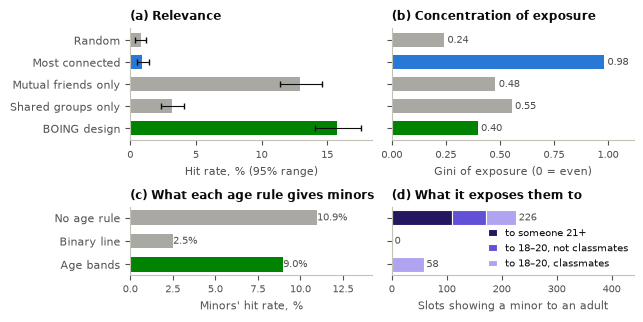

In [15]:
GREY, BLUE, GREEN = br.colour('random'), br.colour('popularity'), br.colour('reranked')
VIOLETS = ['#24165f', '#6250d6', '#b0a4f0']
order = ['Random', 'Most connected', 'Mutual friends only', 'Shared groups only', 'BOING design']
colours = [GREY, BLUE, GREY, GREY, GREEN]
fig, axes = plt.subplots(2, 2, figsize=(br.WIDTH, 3.2), gridspec_kw={'height_ratios': [5, 3], 'hspace': 0.75, 'wspace': 0.08})
t = methods_table.loc[order]
y = np.arange(len(order))[::-1]
ax = axes[0, 0]
ax.barh(y, 100 * t.hit_rate, color=colours, height=0.62)
ax.errorbar(100 * t.hit_rate, y, xerr=[100 * (t.hit_rate - t.hit_low), 100 * (t.hit_high - t.hit_rate)], fmt='none',
            ecolor=br.INK, elinewidth=0.8, capsize=2)
ax.set_yticks(y, order, fontsize=8)
ax.set_xlabel('Hit rate, % (95% range)', fontsize=8)
ax.set_title('(a) Relevance', fontsize=8.5)
ax = axes[0, 1]
ax.barh(y, t.gini, color=colours, height=0.62)
for yy, g in zip(y, t.gini):
    ax.text(g + 0.015, yy, f'{g:.2f}', va='center', fontsize=7.5, color=br.MUTED)
ax.set_yticks(y, [''] * len(y))
ax.set_xlim(0, 1.12); ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xlabel('Gini of exposure (0 = even)', fontsize=8)
ax.set_title('(b) Concentration of exposure', fontsize=8.5)
names = ['No age rule', 'Binary line', 'Age bands']
a = age_rules.loc[['No age rule', 'Binary line (adults and under-18s apart)', "Age bands (the owner's rule)"]]
y2 = np.arange(3)[::-1]
ax = axes[1, 0]
hit = 100 * a['hit_rate (14-17 or unknown)'].to_numpy(dtype=float)
ax.barh(y2, hit, color=[GREY, GREY, GREEN], height=0.62)
for yy, v in zip(y2, hit):
    ax.text(v + 0.03, yy, f'{v:.1f}%', va='center', fontsize=7.5, color=br.MUTED)
ax.set_yticks(y2, names, fontsize=8)
ax.set_xlim(0, hit.max() * 1.3)
ax.set_xlabel("Minors' hit rate, %", fontsize=8)
ax.set_title('(c) What each age rule gives minors', fontsize=8.5)
ax = axes[1, 1]
parts = [('minor to 21+', 'to someone 21+'), ('minor to 18-20, not classmates', 'to 18–20, not classmates'),
         ('minor to 18-20, classmates', 'to 18–20, classmates')]
left = np.zeros(3)
for (col, lab), c in zip(parts, VIOLETS):
    v = a[col].to_numpy(dtype=float)
    ax.barh(y2, v, left=left, color=c, height=0.62, label=lab, edgecolor='white', linewidth=0.8)
    left += v
for yy, v in zip(y2, left):
    ax.text(v + 5, yy, f'{int(v)}', va='center', fontsize=7.5, color=br.MUTED)
ax.set_yticks(y2, [''] * 3)
ax.set_xlim(0, left.max() * 1.95)
ax.set_xlabel('Slots showing a minor to an adult', fontsize=8)
ax.set_title('(d) What it exposes them to', fontsize=8.5)
ax.legend(loc='lower right', fontsize=7, handlelength=1, borderaxespad=0.2)
for ax in axes.flat:
    ax.tick_params(axis='x', labelsize=7.5)
br.save_fig(fig, 'e7_people.png')
plt.show()

## What we learned (version 2)

**The main world.** sim_v1's 5,374 friendships, 1,000 made in class, and 3,000 that close a triangle (focal closure), for 9,374 in
all. The average clustering is 0.153, against 0.007 in the first world, and 73% of friendships share a friend. The test hides
1,875 of them; 1,617 members are tested.

**The weight (practice quiz only).** w = 0.05 has the best NDCG@5 (0.041, tied with 0.1), against 0.019 for w = 1, BOING's
built-in weight. That means mutual friends first, with shared groups breaking ties and filling the list. Weighting groups by
1/log(size) did slightly better (0.043): a lead, not tuned.

**Relevance (H1: holds).**
- The design (w = 0.05) finds a hidden friend for **15.8%** of tested members (95% range 14.0–17.6%; NDCG@5 0.071).
- Mutual friends alone find 12.9% (11.4–14.6%); the ranges barely overlap.
- Shared groups alone find 3.2%, the most-connected people 0.9%, and random 0.8%.
- BOING as built (w = 1) finds 7.4%: shared groups swamp mutual friends, because courses are large.
- **Members with 0 or 1 friends** (28): the design finds a friend for 17.9%, mutual friends alone for 14.3%, and BOING as built
  for 7.1%. Mutual friends alone leave 43% of these members with an empty list; the design leaves none. The slice is small (5 and 4
  members).
- In the first world (no triangle closure), every method is weak: the design 1.7%, shared groups alone 2.0%, mutual friends
  alone 0.6%.

**The rules hold (H2: holds).**
- 0 violations in **72,440** rule checks: every list (36,733), the 243-case age grid (2,480; 138 allowed, 105 refused, all as
  the rule says) and the community with 191 planted cases (33,227).
- No planted case comes back; with the matching rule removed, 166 of them do.
- The checker caught all 18 planted faults.

**Exposure (H3: holds).**
- The design spreads exposure more evenly than any other method that uses the network: Gini 0.40, the top 10% take 25% of the
  slots and 96% of the pool is shown. Mutual friends only: Gini 0.48. Most connected: Gini 0.98, the top 10% take everything.
- Newcomers are still under-exposed: 5.4% of slots for 15.2% of the pool.

**Cost of the rules (H4: holds).**
- Every rule together: 0.120 NDCG@5 (95% range 0.105–0.135), 63% of the unconstrained score.
- Consent costs the most: 0.090 (0.076–0.103). With 25% switched on, the best possible hit rate is 32% (83% with everyone on), and
  the hit rate goes from 8.5% (10% on) to 32.6% (everyone on).
- The safety filters cost 0.024 (private profiles are 22% of the community). The age bands cost 0.006 (0.002–0.011).
- Variety costs nothing.

**The age bands.**
- Minors (14 to 17, or no birth year; 201 tested) find a hidden friend: 10.9% with no age rule, **9.0%** under the bands, 2.5%
  under the binary line.
- Under the bands, no one over 20 is shown a minor (109 slots with no age rule). 18- to 20-year-olds are shown minors only as
  classmates: 58 slots, against 55 classmate and 62 non-classmate slots with no rule.
- Under-14s are never shown and get no list.

**Limits.**
- The closure model, ages, courses and switch shares are assumptions.
- The target clustering (0.15) was lowered from 0.20 because this generator levels off near 0.17, before any test result.
- Ages are drawn independently of the network.

Files: `results/e7_methods.csv`, `e7_few_friends.csv`, `e7_costs.csv`, `e7_age_rules.csv`, `e7_opt_in.csv`, `e7_closure.csv` (the
first world), `e7_validation.csv`, `e7_age_grid.csv`, `e7_rules.json`, `e7_people.json`, `figures/e7_people.png`.
